<a href="https://colab.research.google.com/github/alia-kalim-archive/uk-electricity-demand-forecasting/blob/main/UK_Energy_Markets_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reload the original CSV so we start with all 17,520 rows
df = pd.read_csv("/content/demanddata_2025.csv")

# Standardise column names
df.columns = df.columns.str.strip().str.upper()

# Parse ISO-format dates correctly
df["SETTLEMENT_DATE"] = pd.to_datetime(
    df["SETTLEMENT_DATE"], errors="coerce"
)

# Convert analysis columns to numeric
numeric_cols = [
    "SETTLEMENT_PERIOD",
    "ND",
    "EMBEDDED_WIND_GENERATION",
    "EMBEDDED_SOLAR_GENERATION"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Create useful time variables
df["HOUR"] = ((df["SETTLEMENT_PERIOD"] - 1) // 2).astype("Int64")
df["MONTH"] = df["SETTLEMENT_DATE"].dt.month
df["DAY_OF_WEEK"] = df["SETTLEMENT_DATE"].dt.day_name()

# Remove rows only if essential analysis fields are missing
df = df.dropna(subset=[
    "SETTLEMENT_DATE",
    "SETTLEMENT_PERIOD",
    "ND",
    "EMBEDDED_WIND_GENERATION",
    "EMBEDDED_SOLAR_GENERATION"
])

print("Cleaned rows:", len(df))
print("Date range:", df["SETTLEMENT_DATE"].min(),
      "to", df["SETTLEMENT_DATE"].max())
print("Missing values:")
print(df[numeric_cols].isna().sum())

df.head()


Cleaned rows: 17520
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00
Missing values:
SETTLEMENT_PERIOD            0
ND                           0
EMBEDDED_WIND_GENERATION     0
EMBEDDED_SOLAR_GENERATION    0
dtype: int64


,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW,HOUR,MONTH,DAY_OF_WEEK
0,2025-01-01,1,21036,26215,19918,5405,6606,0,19270,0,...,-232,-386,-558,96,0,241,0,0,1,Wednesday
1,2025-01-01,2,21222,26063,20167,5358,6606,0,19270,0,...,-124,-282,-564,51,0,262,0,0,1,Wednesday
2,2025-01-01,3,21385,25734,20328,5237,6606,0,19270,0,...,-119,-384,-205,62,0,414,0,1,1,Wednesday
3,2025-01-01,4,20473,24988,19460,5115,6606,0,19270,0,...,-119,-334,-193,37,0,423,0,1,1,Wednesday
4,2025-01-01,5,19634,24912,18654,5080,6606,0,19270,0,...,-119,-363,-622,-282,0,288,0,2,1,Wednesday


Monthly electricity-system summary (MW):


,average_demand,peak_demand,minimum_demand,average_embedded_wind,average_embedded_solar
Jan,33302.8,45924,17383,2001.3,623.4
Feb,31677.5,43349,18545,2406.1,954.1
Mar,27456.2,40166,14461,1738.7,2382.8
Apr,23599.8,32831,13917,1414.3,3320.9
May,21706.6,29752,12803,1510.1,3585.3
Jun,21847.5,29638,15082,2002.5,3597.9
Jul,22665.6,29378,15638,1188.0,3179.9
Aug,21808.5,29682,13248,1581.7,2958.8
Sep,23629.2,33391,15452,2038.0,2373.3
Oct,26546.2,37985,15114,2275.6,1145.3


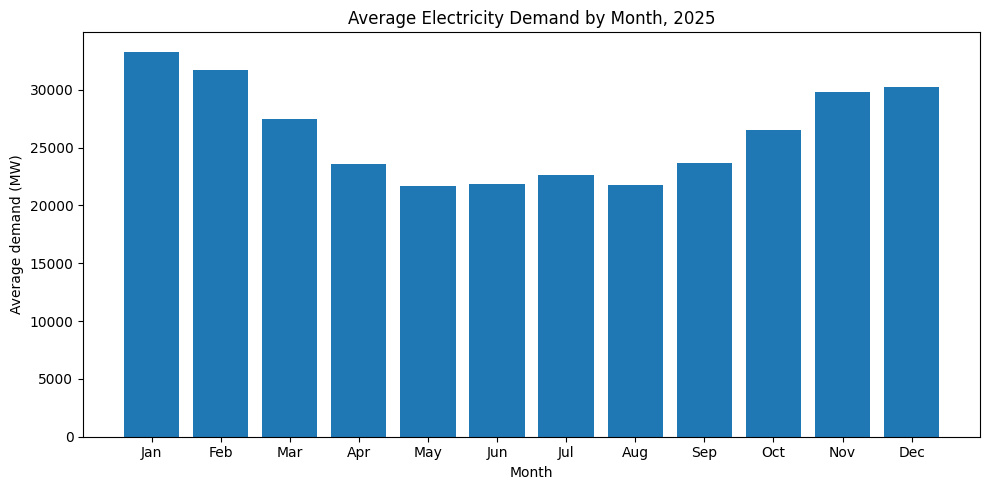

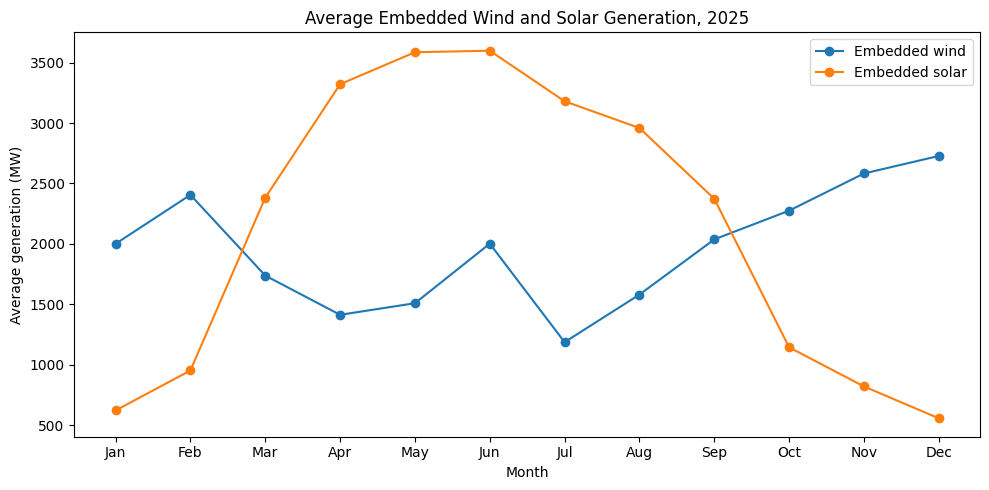

Correlation: demand vs embedded wind = 0.024
Correlation: demand vs embedded solar = -0.258


In [6]:

# Summarise demand and embedded generation by month
monthly = df.groupby("MONTH").agg(
    average_demand=("ND", "mean"),
    peak_demand=("ND", "max"),
    minimum_demand=("ND", "min"),
    average_embedded_wind=("EMBEDDED_WIND_GENERATION", "mean"),
    average_embedded_solar=("EMBEDDED_SOLAR_GENERATION", "mean")
)

monthly.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print("Monthly electricity-system summary (MW):")
display(monthly.round(1))

# Visualise average demand by month
plt.figure(figsize=(10, 5))
plt.bar(monthly.index, monthly["average_demand"])
plt.title("Average Electricity Demand by Month, 2025")
plt.xlabel("Month")
plt.ylabel("Average demand (MW)")
plt.tight_layout()
plt.show()

# Visualise average embedded wind and solar generation
plt.figure(figsize=(10, 5))
plt.plot(
    monthly.index,
    monthly["average_embedded_wind"],
    marker="o",
    label="Embedded wind"
)
plt.plot(
    monthly.index,
    monthly["average_embedded_solar"],
    marker="o",
    label="Embedded solar"
)
plt.title("Average Embedded Wind and Solar Generation, 2025")
plt.xlabel("Month")
plt.ylabel("Average generation (MW)")
plt.legend()
plt.tight_layout()
plt.show()

# Examine demand and embedded wind relationship
print(
    "Correlation: demand vs embedded wind =",
    round(df["ND"].corr(df["EMBEDDED_WIND_GENERATION"]), 3)
)
print(
    "Correlation: demand vs embedded solar =",
    round(df["ND"].corr(df["EMBEDDED_SOLAR_GENERATION"]), 3)
)


Demand by day type (MW):


,average_demand,peak_demand,minimum_demand
Weekday,26967.6,45924,13786
Weekend,24126.4,42824,12803


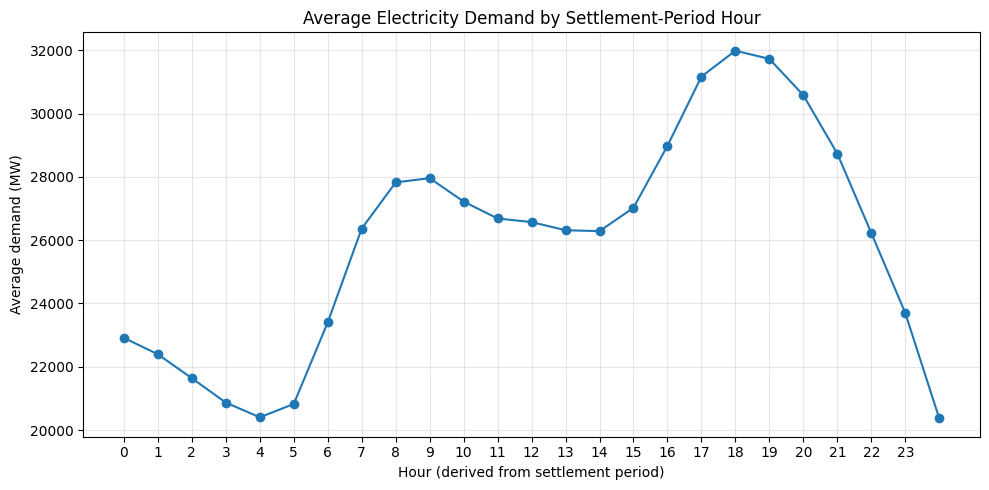

Ten highest-demand observations:


,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION
0,2025-01-09,35,45924,2217,0
1,2025-01-09,36,45881,2212,0
2,2025-01-08,36,45823,884,0
3,2025-01-08,35,45769,850,0
4,2025-01-08,37,45472,879,0
5,2025-01-09,37,45444,2079,0
6,2025-01-09,34,45436,2221,0
7,2025-01-08,34,45405,816,0
8,2025-01-09,38,45367,1945,0
9,2025-01-10,37,45163,949,0


In [7]:

# Classify observations as weekday or weekend
df["IS_WEEKEND"] = df["SETTLEMENT_DATE"].dt.dayofweek >= 5

# Compare average demand
day_type = df.groupby("IS_WEEKEND")["ND"].agg(
    average_demand="mean",
    peak_demand="max",
    minimum_demand="min"
)

day_type.index = ["Weekday", "Weekend"]
print("Demand by day type (MW):")
display(day_type.round(1))

# Average demand across settlement-period hours
hourly = df.groupby("HOUR")["ND"].agg(
    average_demand="mean",
    peak_demand="max"
)

plt.figure(figsize=(10, 5))
plt.plot(hourly.index, hourly["average_demand"], marker="o")
plt.title("Average Electricity Demand by Settlement-Period Hour")
plt.xlabel("Hour (derived from settlement period)")
plt.ylabel("Average demand (MW)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Ten highest-demand observations
top_10 = df.nlargest(10, "ND")[
    ["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "ND",
     "EMBEDDED_WIND_GENERATION", "EMBEDDED_SOLAR_GENERATION"]
]

print("Ten highest-demand observations:")
display(top_10.reset_index(drop=True).round(1))


IS_WEEKEND,Weekday,Weekend,Difference_MW,Difference_pct
HOUR,,,,
0,23016.0,22656.0,360.0,1.6
1,22542.3,22020.4,521.9,2.4
2,21823.8,21174.1,649.8,3.1
3,21105.3,20269.4,835.9,4.1
4,20695.1,19670.6,1024.5,5.2
5,21345.2,19515.0,1830.2,9.4
6,24573.6,20469.3,4104.3,20.1
7,28150.5,21893.7,6256.8,28.6
8,29614.9,23334.9,6280.1,26.9


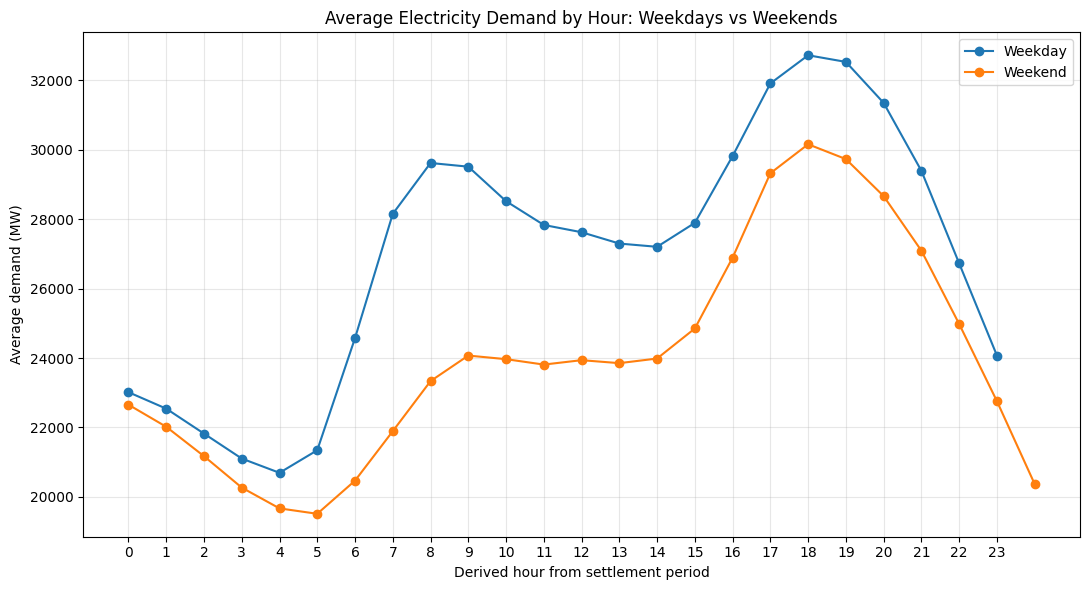

Largest absolute weekday-weekend demand gap:


,Value
IS_WEEKEND,
Weekday,29614.92
Weekend,23334.87
Difference_MW,6280.05
Difference_pct,26.91


Highest average-demand hour on weekdays:
18
Highest average-demand hour on weekends:
18


In [8]:

# Compare average demand by hour and day type
hourly_comparison = df.pivot_table(
    index="HOUR",
    columns="IS_WEEKEND",
    values="ND",
    aggfunc="mean"
)

hourly_comparison = hourly_comparison.rename(
    columns={False: "Weekday", True: "Weekend"}
)

hourly_comparison["Difference_MW"] = (
    hourly_comparison["Weekday"] - hourly_comparison["Weekend"]
)

hourly_comparison["Difference_pct"] = (
    hourly_comparison["Difference_MW"]
    / hourly_comparison["Weekend"] * 100
)

display(hourly_comparison.round(1))

# Plot weekday and weekend profiles
plt.figure(figsize=(11, 6))
plt.plot(
    hourly_comparison.index,
    hourly_comparison["Weekday"],
    marker="o",
    label="Weekday"
)
plt.plot(
    hourly_comparison.index,
    hourly_comparison["Weekend"],
    marker="o",
    label="Weekend"
)

plt.title("Average Electricity Demand by Hour: Weekdays vs Weekends")
plt.xlabel("Derived hour from settlement period")
plt.ylabel("Average demand (MW)")
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Identify hours with the largest weekday-weekend gap
print("Largest absolute weekday-weekend demand gap:")
display(
    hourly_comparison.loc[
        hourly_comparison["Difference_MW"].idxmax()
    ].to_frame("Value").round(2)
)

print("Highest average-demand hour on weekdays:")
print(hourly_comparison["Weekday"].idxmax())

print("Highest average-demand hour on weekends:")
print(hourly_comparison["Weekend"].idxmax())


IS_WEEKEND,Weekday,Weekend,Difference_MW,Difference_pct
HOUR,,,,
0,23016.0,22656.0,360.0,1.6
1,22542.3,22020.4,521.9,2.4
2,21823.8,21174.1,649.8,3.1
3,21105.3,20269.4,835.9,4.1
4,20695.1,19670.6,1024.5,5.2
5,21345.2,19515.0,1830.2,9.4
6,24573.6,20469.3,4104.3,20.1
7,28150.5,21893.7,6256.8,28.6
8,29614.9,23334.9,6280.1,26.9


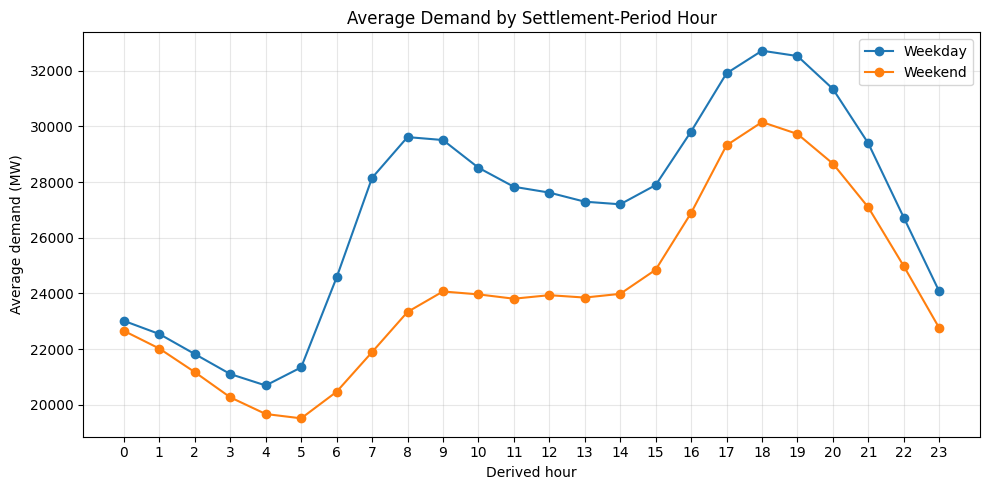

In [9]:

# Restrict the simple hourly comparison to standard settlement periods
standard_day = df[df["SETTLEMENT_PERIOD"].between(1, 48)].copy()

hourly_clean = standard_day.pivot_table(
    index="HOUR",
    columns="IS_WEEKEND",
    values="ND",
    aggfunc="mean"
).rename(columns={False: "Weekday", True: "Weekend"})

hourly_clean["Difference_MW"] = (
    hourly_clean["Weekday"] - hourly_clean["Weekend"]
)

hourly_clean["Difference_pct"] = (
    hourly_clean["Difference_MW"]
    / hourly_clean["Weekend"] * 100
)

display(hourly_clean.round(1))

plt.figure(figsize=(10, 5))
plt.plot(hourly_clean.index, hourly_clean["Weekday"],
         marker="o", label="Weekday")
plt.plot(hourly_clean.index, hourly_clean["Weekend"],
         marker="o", label="Weekend")
plt.title("Average Demand by Settlement-Period Hour")
plt.xlabel("Derived hour")
plt.ylabel("Average demand (MW)")
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

analysis = df.copy()

# Keep standard settlement periods
analysis = analysis[
    analysis["SETTLEMENT_PERIOD"].between(1, 48)
].copy()

# Convert columns to standard numeric types
analysis["ND"] = pd.to_numeric(analysis["ND"], errors="coerce").astype(float)
analysis["EMBEDDED_WIND_GENERATION"] = pd.to_numeric(
    analysis["EMBEDDED_WIND_GENERATION"], errors="coerce"
).astype(float)
analysis["EMBEDDED_SOLAR_GENERATION"] = pd.to_numeric(
    analysis["EMBEDDED_SOLAR_GENERATION"], errors="coerce"
).astype(float)

# Recreate time variables using standard integer types
analysis["HOUR"] = (
    (analysis["SETTLEMENT_PERIOD"].astype(int) - 1) // 2
).astype(int)

analysis["MONTH"] = (
    analysis["SETTLEMENT_DATE"].dt.month
).astype(int)

analysis["DAY_OF_WEEK_NUM"] = (
    analysis["SETTLEMENT_DATE"].dt.dayofweek
).astype(int)

analysis["IS_WEEKEND"] = (
    analysis["DAY_OF_WEEK_NUM"] >= 5
).astype(int)

# Remove any missing modelling values
model_cols = [
    "ND", "HOUR", "MONTH", "IS_WEEKEND",
    "EMBEDDED_WIND_GENERATION", "EMBEDDED_SOLAR_GENERATION"
]
analysis = analysis.dropna(subset=model_cols)

# Fit multiple regression with HAC standard errors
model = smf.ols(
    formula=(
        "ND ~ C(HOUR) + C(MONTH) + IS_WEEKEND "
        "+ EMBEDDED_WIND_GENERATION "
        "+ EMBEDDED_SOLAR_GENERATION"
    ),
    data=analysis
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 48}
)

print("Observations:", int(model.nobs))
print(model.summary())


Observations: 17518
                            OLS Regression Results                            
Dep. Variable:                     ND   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.900
Method:                 Least Squares   F-statistic:                     809.5
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:31:23   Log-Likelihood:            -1.5759e+05
No. Observations:               17518   AIC:                         3.152e+05
Df Residuals:                   17480   BIC:                         3.155e+05
Df Model:                          37                                         
Covariance Type:                  HAC                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
In

Training observations: 12766
Testing observations: 4418
Test period: 2025-10-01 00:00:00 to 2025-12-31 00:00:00


,Model,MAE_MW,RMSE_MW
0,Previous-day baseline,1907.0,2627.2
1,Random forest,1537.1,1985.1


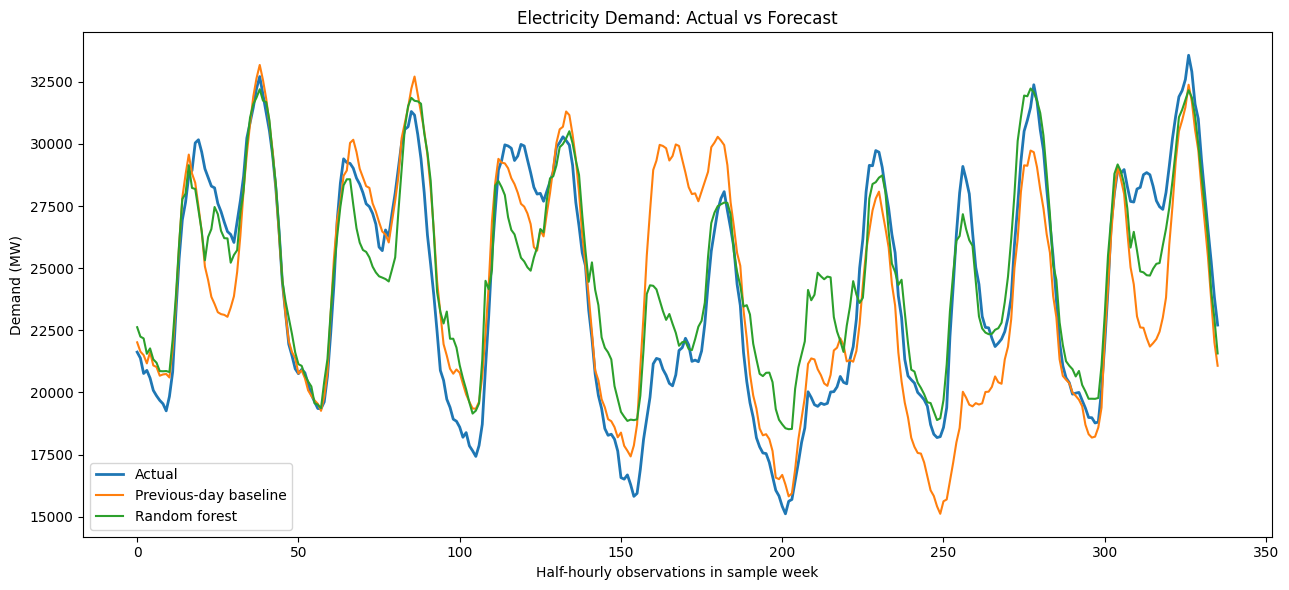

Random forest feature importance:


,Importance
LAG_48,0.796
LAG_336,0.112
ROLLING_MEAN_48,0.034
DAY_OF_WEEK,0.020
PERIOD_COS,0.017
PERIOD_SIN,0.013
MONTH,0.007
IS_WEEKEND,0.002


In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prepare data in chronological order
forecast = df.copy()

forecast["SETTLEMENT_DATE"] = pd.to_datetime(
    forecast["SETTLEMENT_DATE"]
)
forecast = forecast.sort_values(
    ["SETTLEMENT_DATE", "SETTLEMENT_PERIOD"]
).reset_index(drop=True)

forecast["DAY_OF_WEEK"] = (
    forecast["SETTLEMENT_DATE"].dt.dayofweek
)
forecast["MONTH"] = forecast["SETTLEMENT_DATE"].dt.month
forecast["IS_WEEKEND"] = (
    forecast["DAY_OF_WEEK"] >= 5
).astype(int)

# Cyclical time features
forecast["PERIOD_SIN"] = np.sin(
    2 * np.pi * (forecast["SETTLEMENT_PERIOD"] - 1) / 48
)
forecast["PERIOD_COS"] = np.cos(
    2 * np.pi * (forecast["SETTLEMENT_PERIOD"] - 1) / 48
)

# Lag features: past demand only
forecast["LAG_48"] = forecast["ND"].shift(48)
forecast["LAG_336"] = forecast["ND"].shift(336)

# Rolling mean must exclude the current observation
forecast["ROLLING_MEAN_48"] = (
    forecast["ND"].shift(1).rolling(48).mean()
)

features = [
    "DAY_OF_WEEK", "MONTH", "IS_WEEKEND",
    "PERIOD_SIN", "PERIOD_COS",
    "LAG_48", "LAG_336", "ROLLING_MEAN_48"
]

forecast = forecast.dropna(
    subset=features + ["ND", "SETTLEMENT_DATE"]
).copy()

# Chronological train/test split
train = forecast[
    forecast["SETTLEMENT_DATE"] < "2025-10-01"
].copy()

test = forecast[
    forecast["SETTLEMENT_DATE"] >= "2025-10-01"
].copy()

X_train = train[features]
y_train = train["ND"]
X_test = test[features]
y_test = test["ND"]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print(
    "Test period:",
    test["SETTLEMENT_DATE"].min(),
    "to",
    test["SETTLEMENT_DATE"].max()
)

# Baseline: previous day's corresponding observation
baseline_predictions = test["LAG_48"].to_numpy()

# Random forest model
rf = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
rf_predictions = rf.predict(X_test)

# Evaluation
def evaluate(actual, predicted, name):
    return {
        "Model": name,
        "MAE_MW": mean_absolute_error(actual, predicted),
        "RMSE_MW": np.sqrt(mean_squared_error(actual, predicted))
    }

results = pd.DataFrame([
    evaluate(y_test, baseline_predictions, "Previous-day baseline"),
    evaluate(y_test, rf_predictions, "Random forest")
])

display(results.round(1))

# Plot a sample week of actual and predicted demand
plot_data = test.copy()
plot_data["Actual"] = y_test.to_numpy()
plot_data["Baseline"] = baseline_predictions
plot_data["Random_Forest"] = rf_predictions

sample = plot_data[
    plot_data["SETTLEMENT_DATE"] < "2025-10-08"
]

plt.figure(figsize=(13, 6))
plt.plot(sample["Actual"].to_numpy(), label="Actual", linewidth=2)
plt.plot(sample["Baseline"].to_numpy(), label="Previous-day baseline")
plt.plot(sample["Random_Forest"].to_numpy(), label="Random forest")
plt.title("Electricity Demand: Actual vs Forecast")
plt.xlabel("Half-hourly observations in sample week")
plt.ylabel("Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

# Feature importance
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values(ascending=False)

print("Random forest feature importance:")
display(importance.to_frame("Importance").round(3))


In [13]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# Add historical renewable-generation features
forecast = forecast.sort_values(
    ["SETTLEMENT_DATE", "SETTLEMENT_PERIOD"]
).copy()

for col in ["EMBEDDED_WIND_GENERATION", "EMBEDDED_SOLAR_GENERATION"]:
    forecast[f"{col}_LAG_48"] = forecast[col].shift(48)
    forecast[f"{col}_LAG_336"] = forecast[col].shift(336)

renewable_features = [
    "EMBEDDED_WIND_GENERATION_LAG_48",
    "EMBEDDED_WIND_GENERATION_LAG_336",
    "EMBEDDED_SOLAR_GENERATION_LAG_48",
    "EMBEDDED_SOLAR_GENERATION_LAG_336"
]

base_features = [
    "DAY_OF_WEEK", "MONTH", "IS_WEEKEND",
    "PERIOD_SIN", "PERIOD_COS",
    "LAG_48", "LAG_336", "ROLLING_MEAN_48"
]

all_features = base_features + renewable_features

# Use the same rows for both models
forecast_model = forecast.dropna(
    subset=all_features + ["ND"]
).copy()

train2 = forecast_model[
    forecast_model["SETTLEMENT_DATE"] < "2025-10-01"
].copy()

test2 = forecast_model[
    forecast_model["SETTLEMENT_DATE"] >= "2025-10-01"
].copy()

# Model A: current features
model_a = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
model_a.fit(train2[base_features], train2["ND"])
pred_a = model_a.predict(test2[base_features])

# Model B: add historical wind and solar
model_b = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
model_b.fit(train2[all_features], train2["ND"])
pred_b = model_b.predict(test2[all_features])

# Compare on the identical test observations
comparison = pd.DataFrame([
    {
        "Model": "Base random forest",
        "MAE_MW": mean_absolute_error(test2["ND"], pred_a),
        "RMSE_MW": np.sqrt(mean_squared_error(test2["ND"], pred_a))
    },
    {
        "Model": "RF + lagged embedded wind/solar",
        "MAE_MW": mean_absolute_error(test2["ND"], pred_b),
        "RMSE_MW": np.sqrt(mean_squared_error(test2["ND"], pred_b))
    }
])

display(comparison.round(1))

# Calculate improvement in MAE
mae_a = comparison.loc[0, "MAE_MW"]
mae_b = comparison.loc[1, "MAE_MW"]

print(
    "MAE improvement from adding renewable features:",
    round((mae_a - mae_b) / mae_a * 100, 2),
    "%"
)

# Feature importance from the enhanced model
importance = pd.Series(
    model_b.feature_importances_,
    index=all_features
).sort_values(ascending=False)

display(importance.to_frame("Importance").round(3))


,Model,MAE_MW,RMSE_MW
0,Base random forest,1572.8,2023.1
1,RF + lagged embedded wind/solar,1589.1,2056.3


MAE improvement from adding renewable features: -1.03 %


,Importance
LAG_336,0.567
LAG_48,0.326
ROLLING_MEAN_48,0.024
EMBEDDED_WIND_GENERATION_LAG_336,0.018
DAY_OF_WEEK,0.016
EMBEDDED_WIND_GENERATION_LAG_48,0.012
EMBEDDED_SOLAR_GENERATION_LAG_48,0.009
PERIOD_SIN,0.008
PERIOD_COS,0.008
EMBEDDED_SOLAR_GENERATION_LAG_336,0.007


In [14]:

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Keep the same training and test observations
features = base_features

ai_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

ai_model.fit(train2[features], train2["ND"])
ai_predictions = ai_model.predict(test2[features])

# Compare with the Random Forest on identical observations
results_ai = pd.DataFrame([
    {
        "Model": "Previous-day baseline",
        "MAE_MW": mean_absolute_error(
            test2["ND"], test2["LAG_48"]
        ),
        "RMSE_MW": np.sqrt(
            mean_squared_error(test2["ND"], test2["LAG_48"])
        )
    },
    {
        "Model": "Random Forest",
        "MAE_MW": mean_absolute_error(
            test2["ND"], model_a.predict(test2[base_features])
        ),
        "RMSE_MW": np.sqrt(
            mean_squared_error(
                test2["ND"], model_a.predict(test2[base_features])
            )
        )
    },
    {
        "Model": "Gradient Boosting",
        "MAE_MW": mean_absolute_error(
            test2["ND"], ai_predictions
        ),
        "RMSE_MW": np.sqrt(
            mean_squared_error(test2["ND"], ai_predictions)
        )
    }
])

display(results_ai.round(1))


,Model,MAE_MW,RMSE_MW
0,Previous-day baseline,1907.0,2627.2
1,Random Forest,1572.8,2023.1
2,Gradient Boosting,1445.9,1845.6


In [15]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

peak_results = test2[["ND", "LAG_48"]].copy()
peak_results["Random_Forest"] = model_a.predict(
    test2[base_features]
)
peak_results["Gradient_Boosting"] = ai_model.predict(
    test2[base_features]
)

# Define peak demand as the top 10% of actual demand in the test period
peak_threshold = peak_results["ND"].quantile(0.90)
peak = peak_results[peak_results["ND"] >= peak_threshold]

def metrics(actual, predicted):
    return {
        "MAE_MW": mean_absolute_error(actual, predicted),
        "RMSE_MW": np.sqrt(mean_squared_error(actual, predicted))
    }

rows = []

for name, column in [
    ("Previous-day baseline", "LAG_48"),
    ("Random Forest", "Random_Forest"),
    ("Gradient Boosting", "Gradient_Boosting")
]:
    rows.append({
        "Model": name,
        **metrics(peak["ND"], peak[column])
    })

print(f"Peak-demand threshold: {peak_threshold:,.0f} MW")
print(f"Peak observations: {len(peak):,}")
display(pd.DataFrame(rows).round(1))


Peak-demand threshold: 36,732 MW
Peak observations: 442


,Model,MAE_MW,RMSE_MW
0,Previous-day baseline,2304.0,3210.2
1,Random Forest,1860.0,2362.1
2,Gradient Boosting,1632.9,2093.6


In [16]:
%pip install -q shap

In [18]:

import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use training data as the reference distribution
background = train2[base_features].sample(
    n=min(50, len(train2)),
    random_state=42
)

# Explain a manageable sample of unseen test observations
explain_data = test2[base_features].sample(
    n=min(100, len(test2)),
    random_state=42
)

# Explicitly use the permutation explainer
explainer = shap.PermutationExplainer(
    ai_model.predict,
    background
)

shap_values = explainer(
    explain_data,
    max_evals=10 * (2 * len(base_features) + 1),
    silent=True
)

print("SHAP analysis complete.")
print("Observations explained:", len(explain_data))
print("Features analysed:", len(base_features))


SHAP analysis complete.
Observations explained: 100
Features analysed: 8


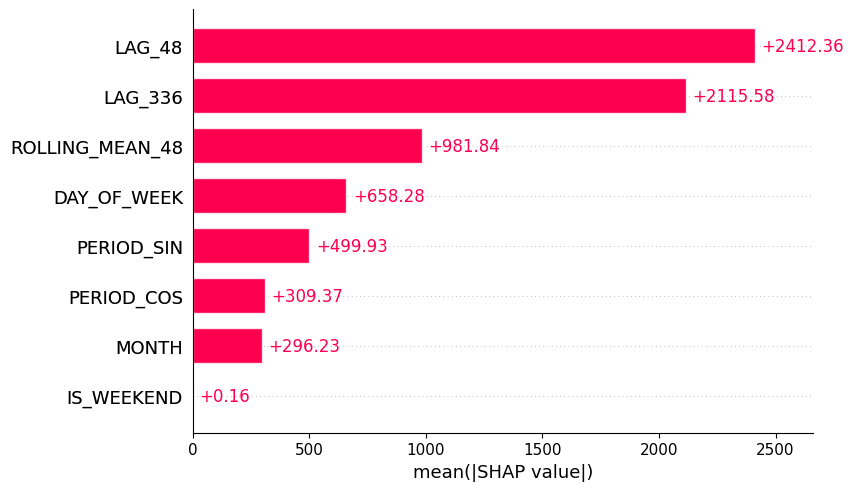

In [19]:

shap.plots.bar(shap_values, max_display=10)
plt.show()


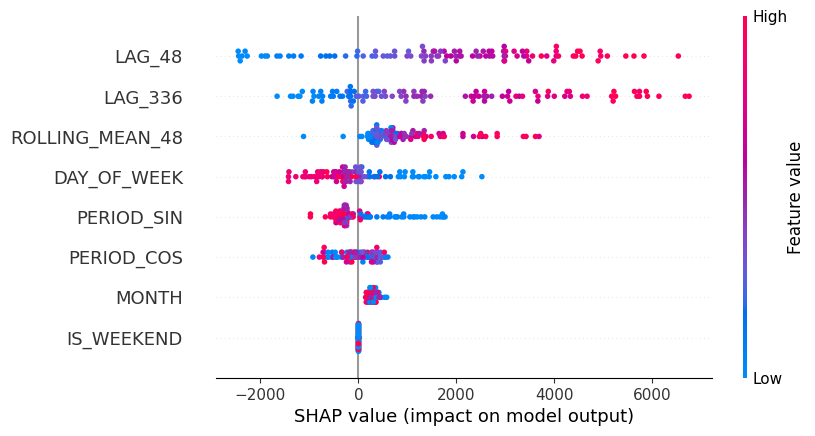

In [20]:

shap.plots.beeswarm(shap_values, max_display=10)
plt.show()


In [21]:

shap_importance = pd.DataFrame({
    "Feature": base_features,
    "Mean_Absolute_SHAP_MW": np.abs(shap_values.values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP_MW", ascending=False)

display(shap_importance.round(2))


,Feature,Mean_Absolute_SHAP_MW
5,LAG_48,2412.36
6,LAG_336,2115.58
7,ROLLING_MEAN_48,981.84
0,DAY_OF_WEEK,658.28
3,PERIOD_SIN,499.93
4,PERIOD_COS,309.37
1,MONTH,296.23
2,IS_WEEKEND,0.16
